# Calculateur CO₂ logistique : le pipeline de data wrangling pas à pas

Projet FastColis. Objectif : construire un **dataset unifié et propre** donnant l'émission de CO₂ de chaque
colis, à partir de sources hétérogènes et incomplètes, puis l'exposer à nos clients grands comptes.

Ce notebook ne contient pas la logique : il appelle les modules du paquet `co2` dans l'ordre des étapes
du cours (découverte, ingestion, structuration et nettoyage, enrichissement, mapping et feature
engineering, validation, publication) et montre ce que chacune produit. Pour tout relancer d'un bloc :
`python run_pipeline.py`.

In [1]:
import sys, json
from pathlib import Path
RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RACINE))
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 30, "display.width", 200)
from co2 import config as C, ingestion, decouverte, nettoyage, referentiels as R

## 0. Les sources

| Source | Format | Contenu | Nature |
|---|---|---|---|
| Export SAP | CSV Windows-1252, `;`, virgule décimale | commandes, clients, poids, dimensions, service | fictive |
| Flashages | 12 fichiers JSON Lines, deux firmwares | scans des colis : site, heure, GPS, transporteur | fictive |
| Annuaire transporteurs | Excel, 2 onglets aux colonnes différentes | flotte interne et sous-traitants | fictive |
| Référentiel des sites | CSV | plateformes, agences, entrepôts | fictive (villes réelles) |
| Base Carbone ADEME | CSV latin-1, 18 616 lignes | facteurs d'émission officiels | **réelle** |
| GeoNames cities5000 | TSV | villes, coordonnées, population, fuseau | **réelle** |
| OpenFlights | CSV | aéroports (codes IATA, coordonnées) | **réelle** |
| OSRM (OpenStreetMap) | API | distances routières réelles entre sites | **réelle** |
| searoute | bibliothèque | distances maritimes réelles | **réelle** |

Les sources internes sont simulées (le cours l'autorise) avec les défauts que l'on rencontre en vrai.
Comme on connaît leur vérité terrain, on peut **mesurer** la qualité du pipeline, ce qui serait impossible
sur de vraies données.

## 1. Découverte

Premier réflexe : réduire chaque valeur à sa forme (chiffre → 9, lettre → A) pour voir les formats concurrents sans écrire de règle.

In [2]:
raw = ingestion.ingerer()
for nom, df in raw.items():
    print(f"{nom:32s} {len(df):>8,} lignes  {df.shape[1]:>3} colonnes".replace(",", " "))

sap                                61 020 lignes   26 colonnes
flashages                         362 199 lignes   10 colonnes
transporteurs_internes                 44 lignes    6 colonnes
transporteurs_sous_traitants           66 lignes    8 colonnes
sites                                 129 lignes    7 colonnes
sites_alias                             8 lignes    2 colonnes


In [3]:
for c in decouverte.constats(raw):
    print("•", c)

• SAP : 61 020 lignes pour 60 000 numéros de suivi, soit 1 020 lignes en double.
• SAP : formats de date ERDAT rencontrés : `9{8}` (51 596), `99.99.9{4}` (6 449), `9{4}-99-99` (2 975).
• SAP : unités de poids GEWEI : KG (54 451), G (4 734), vide (1 835).
• SAP : 1 568 poids illisibles ou vides, 132 nuls ou négatifs, 1 158 poids > 70 « kg » (probablement des grammes).
• SAP : 22 libellés clients pour 8 codes clients.
• SAP : 37 écritures de pays d'origine (Allemagne, BE, Belgique, CA, CHN, CN, Canada, Chine, Corée du Sud, DE, DEU, ES...).
• SAP : codes de service VSART : 01, 02, 03, 04, ECO, EXP, Express 24h, INT, International, STD, Standard, Écologique.
• Flashages : 362 199 événements, 159 599 au format v1 (epoch en ms, codes courts) et 202 600 au format v2 (ISO 8601).
• Flashages : codes d'événements : ARRIVEE_AGENCE, ARR_NCE, DEPART_TOURNEE, DEPOT_RELAIS, DEP_NEE, ENTREE_PLATEFORME, ENT_RME, HUB_PARTENAIRE, LIVRE, LIVRE_RELAIS, LIV_AIS, LIV_VRE, PRISE_EN_CHARGE, PRI_RGE, TRI, TRI_T

In [4]:
decouverte.profiler(raw["sap"]).head(14)

,colonne,manquants_pct,distincts,formes,valeurs_frequentes
0,VBELN,0.0,59986,`9{8}` 100%,"75031276 (3), 13011968 (3), 79592945 (3)"
1,TRACKING,0.0,60000,`AA9{10}` 100%,"FC4755401484 (3), FC9212375976 (3), FC38599366..."
2,KUNNR,0.0,8,`9{6}` 100%,"100100 (20104), 100107 (13357), 100114 (6710)"
3,NAME1,0.0,22,`A{6}` 23% | `A{6} A{6} A{10}` 8% | `A{6} AA A...,"AMAZON FRANCE LOGISTIQUE (5093), Amazon (5039)..."
4,MATKL,0.0,8,`A{6}` 50% | `A{4}` 13% | `A{9}` 13% | `A{5}` 13%,"Mode (7865), Bricolage (7653), Livres (7640)"
5,BRGEW,2.6,9008,"`9,999` 78% | `9,99` 8% | `999` 6% | `9{4}` 4%","0,457 (59), 0,484 (59), 0,458 (59)"
6,GEWEI,3.0,2,`AA` 89% | `A` 8% | `∅` 3%,"KG (54451), G (4734)"
7,LAENG,12.0,1105,`99.9` 78% | `∅` 12% | `999.9` 10% | `9.9` 0%,"19.3 (330), 17.9 (326), 16.9 (324)"
8,BREIT,12.0,899,`99.9` 71% | `∅` 12% | `999.9` 9% | `9.9` 8%,"12.7 (423), 13.0 (410), 13.9 (410)"
9,HOEHE,12.0,722,`99.9` 46% | `9.9` 37% | `∅` 12% | `999.9` 6%,"8.9 (477), 9.4 (470), 10.6 (458)"


In [5]:
raw["flashages"].groupby("firmware").head(2)

,firmware,tracking,evenement,site,horodatage,lat,lon,transporteur,_fichier,_ligne
0,v2,FC8374683489,ENTREE_PLATEFORME,ENT-CDG,2025-10-14T13:17:53+02:00,49.012798,2.55,NaN,flashages_2025-10.jsonl,1
1,v2,FC8374683489,ARRIVEE_AGENCE,ag-75,2025-10-15T08:53:14+02:00,48.85341,2.3488,ST-021,flashages_2025-10.jsonl,2
5,v1,FC1498844966,TRI_TRI,TRI-IDF,1759886037523,48.98693,2.44892,ST-008,flashages_2025-10.jsonl,6
6,v1,FC1498844966,TRI_TRI,TRI-DIJ,1759935120382,47.31344,5.01391,ST-006,flashages_2025-10.jsonl,7


## 2. Ingestion

Chaque lecteur garde tout en texte et ajoute la traçabilité (`_fichier`, `_ligne`). Les deux formats de scanners sont ramenés à un même schéma brut. Les tables sont figées en Parquet dans `data/raw`.

In [6]:
raw["sap"][["TRACKING", "NAME1", "BRGEW", "GEWEI", "VSART", "LAND1_ORIG", "ERDAT", "_fichier", "_ligne"]].sample(6, random_state=1)

,TRACKING,NAME1,BRGEW,GEWEI,VSART,LAND1_ORIG,ERDAT,_fichier,_ligne
23472,FC9330981784,AMAZON EU SARL,"1,548",KG,INT,USA,20260518,sap_export_colis.csv,23474
6055,FC7923170081,Leroy-Merlin,"5,652",KG,02,fr,20260526,sap_export_colis.csv,6057
50435,FC8381052340,Decathlon,"1,763",KG,03,FRA,20260504,sap_export_colis.csv,50437
36349,FC8428084753,CDISCOUNT SA,"10,914",KG,03,fr,20260527,sap_export_colis.csv,36351
19649,FC8238385780,AMAZON EU SARL,"1,146",KG,Express 24h,FR,20260617,sap_export_colis.csv,19651
26089,FC4953646316,SHEIN DIST. CORP,"0,593",KG,04,CHN,20251211,sap_export_colis.csv,26091


## 3. Structuration et nettoyage

Renommage des colonnes SAP en noms métier, conversion des unités, dates, codes, doublons. Chaque règle est inscrite au journal.

In [7]:
rc = nettoyage.nettoyer(raw)
rc["journal_nettoyage"]

,table,regle,lignes,action
0,sap,libellés clients,22,22 libellés ramenés à 8 clients via le code KUNNR
1,sap,poids en grammes (unité G),4734,divisé par 1 000
2,sap,poids > 70 kg avec unité KG ou vide,1334,valeur en grammes : divisée par 1 000
3,sap,poids nul ou négatif,132,mis à vide puis imputé
4,sap,dimensions en mm,6220,converties en cm
5,sap,dimension > 2 m,0,volume mis à vide
6,sap,codes de service,12,12 écritures ramenées à 4 services
7,sap,codes pays,37,37 écritures ramenées à 14 codes ISO 3166
8,sap,formats de date,9424,trois formats convertis en datetime
9,sap,doublons de numéro de suivi,1020,"supprimés (755 copies exactes, 265 réexportati..."


In [8]:
rc["colis"].head()

,tracking_id,commande_id,client,client_code,categorie,poids_kg,poids_corrige,longueur_cm,largeur_cm,hauteur_cm,volume_m3,service,livraison,pays_origine,ville_origine_brute,site_expedition,pays_destination,ville_destination_brute,departement_destination,date_commande,montant,devise,mode_paiement
0,FC1000169559,65314564,VINTED,100107,Bricolage,0.957,False,NaN,NaN,NaN,NaN,standard,domicile,FR,Clichy-sous-Bois,None,FR,SALON-DE-PROVENCE,13,2025-11-22 17:53:52,13.30,EUR,CB
1,FC1000616553,46202169,SHEIN,100121,Mode,0.215,False,13.0,10.1,3.6,0.000473,international,point_relais,CN,Shenzhen,None,FR,Pessac,33,2025-10-15 12:46:34,105.44,EUR,CB
2,FC1000730070,54236895,VINTED,100107,Livres,0.416,False,14.8,11.7,7.1,0.001229,ecologique,domicile,FR,Châtillon-sur-Seine,None,FR,Issoire,63,2025-11-14 15:45:04,7.70,EUR,CB
3,FC1001017963,25596700,AMAZON,100100,Jouets,1.531,False,40.0,11.4,11.4,0.005198,express,domicile,FR,Saran,WH-AMA1,FR,St-Dié-des-Vosges,88,2026-09-19 16:16:22,33.98,EUR,CB
4,FC1001209556,12309547,AMAZON,100100,Mode,0.959,False,24.7,16.0,10.0,0.003952,ecologique,domicile,FR,AMIENS,WH-AMA5,FR,Strasbourg,67,2026-02-18 12:11:18,47.63,EUR,PAYPAL


In [9]:
rc["transporteurs"][["transporteur_id", "libelle_vehicule", "energie", "code_vehicule"]].sample(8, random_state=3)

,transporteur_id,libelle_vehicule,energie,code_vehicule
71,ST-028,"Utilitaire 3,5 t",Gazole,VUL_DIESEL
99,ST-056,Fret aérien long-courrier,Électrique,AIR
6,FC-007,Semi 40T GNV,GNV,ROUTE_ART_40T_GNC
5,FC-006,SEMI 44T gazole,NaN,ROUTE_ART_40T_DIESEL
90,ST-047,Fourgon GNV,NaN,VUL_GNC
88,ST-045,Fourgon élec 3.5T,Électrique,VUL_ELEC
40,FC-041,Fourgon GNV,GNV,VUL_GNC
55,ST-012,Semi 40T GNV,GNV,ROUTE_ART_40T_GNC


## 4. Enrichissement

Facteurs ADEME extraits par identifiant (jamais recopiés à la main), géocodage, topologie du réseau apprise depuis les scans, reconstitution des trajets, distances par mode.

In [10]:
R.table_facteurs()[["code_vehicule", "libelle", "kgco2e_tkm", "base_carbone_id", "statut_source"]]

,code_vehicule,libelle,kgco2e_tkm,base_carbone_id,statut_source
0,ROUTE_ART_40T_DIESEL,"Articulé 34 à 40 t, gazole B7",0.08750,43643,Valide générique
1,ROUTE_ART_40T_GNC,"Articulé 34 à 40 t, GNC",0.09860,43644,Valide générique
2,ROUTE_ART_40T_GNL,"Articulé 34 à 40 t, GNL",0.10300,43645,Valide générique
3,ROUTE_RIG_20T_DIESEL,"Porteur 12 à 20 t, gazole B7",0.16900,43716,Valide générique
4,ROUTE_RIG_12T_DIESEL,"Porteur 7,5 à 12 t, gazole B7",0.25700,43724,Valide générique
5,ROUTE_RIG_7T_DIESEL,"Porteur 3,5 à 7,5 t, gazole B7",0.40100,43722,Valide générique
6,ROUTE_RIG_7T_ELEC,"Porteur 3,5 à 7,5 t, électrique",0.05800,28030,Valide générique
7,VUL_DIESEL,"Utilitaire < 3,5 t, gazole B7",0.84200,43735,Valide générique
8,VUL_ESSENCE,"Utilitaire < 3,5 t, essence",0.92000,43736,Valide générique
9,VUL_GNC,"Utilitaire < 3,5 t, GNC",1.07000,43737,Valide générique


In [11]:
etapes = pd.read_parquet(C.ENRICHED / "etapes.parquet")
exemple = etapes.tracking_id.iloc[0]
etapes[etapes.tracking_id == exemple][["rang", "de", "vers", "type_etape", "vers_infere", "distance_vol_oiseau_km", "distance_km", "methode_distance"]]

,rang,de,vers,type_etape,vers_infere,distance_vol_oiseau_km,distance_km,methode_distance
0,0,ORIGINE,AG-93,COLLECTE,False,9.535039,19.36,vol_oiseau_x_detour_tournee
1,1,AG-93,TRI-IDF,CAPILLAIRE_ORIGINE,False,13.658882,19.26,osrm
2,2,TRI-IDF,TRI-NAT,LIGNE,False,122.780020,152.45,osrm
3,3,TRI-NAT,TRI-MRS,LIGNE,False,563.660525,740.52,osrm
4,4,TRI-MRS,AG-13,CAPILLAIRE,False,21.055075,24.44,osrm
5,5,AG-13,DESTINATION,DERNIER_KM,False,43.723612,88.77,vol_oiseau_x_detour_tournee


In [12]:
etapes.methode_distance.value_counts()

methode_distance
osrm                           176568
vol_oiseau_x_detour_tournee     72114
orthodromie_plus_95km            6915
vol_oiseau_x_detour              6507
route_maritime                    896
Name: count, dtype: int64

## 5. Mapping, feature engineering et apprentissage

Chaque étape reçoit un véhicule : celui du transporteur quand il est connu, sinon une prédiction. Trois modèles sont comparés à une règle simple :

In [13]:
resume = json.loads((C.REPORTS / "resume_pipeline.json").read_text())
pd.DataFrame(resume["metriques_modeles"]).T

,n_apprentissage,n_test,precision_modele,precision_regle_pays,precision_regle_frequence,r2_log,erreur_absolue_mediane_pct,erreur_absolue_mediane_pct_naif,mae_g,couverture_intervalle_80,marge_conformale_log
Mode des colis internationaux (porte d'entrée non flashée),5505.0,1836.0,0.985294,0.874183,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Véhicule d'une étape sans transporteur,148412.0,37104.0,0.706528,NaN,0.697283,NaN,NaN,NaN,NaN,NaN,NaN
Émission d'un colis à partir de la commande,21445.0,7149.0,NaN,NaN,NaN,0.870385,16.826738,55.728751,199.197423,0.793817,0.043352


In [14]:
cur = pd.read_parquet(C.CURATED / "colis_co2.parquet")
cur[["tracking_id", "date_first_scan", "date_last_scan", "pays_origine", "pays_destination", "poids_kg", "volume_m3",
     "nb_plateformes", "distance_estimee_km", "mode_transport", "facteur_emission_moyen_g_tkm",
     "emission_estimee_g", "emission_ml_g", "taux_observation"]].head(8)

,tracking_id,date_first_scan,date_last_scan,pays_origine,pays_destination,poids_kg,volume_m3,nb_plateformes,distance_estimee_km,mode_transport,facteur_emission_moyen_g_tkm,emission_estimee_g,emission_ml_g,taux_observation
0,FC1000169559,2025-11-23 04:45:30,2025-11-24 22:06:38.393,FR,FR,0.957,NaN,5,1044.8,Camion,171.9,171.84,128.80,0.667
1,FC1000616553,2025-10-17 09:44:50,2025-10-19 15:19:46.017,CN,FR,0.215,0.000473,4,10335.5,Avion,951.8,2115.04,2059.30,0.600
2,FC1000730070,2025-11-14 21:27:07,2025-11-16 14:33:28.000,FR,FR,0.416,0.001229,4,583.9,Camion,342.1,83.09,31.81,0.600
3,FC1001017963,2026-09-19 20:26:22,2026-09-20 21:54:13.000,FR,FR,1.531,0.005198,3,850.9,Camion,182.9,238.21,156.70,1.000
4,FC1001209556,2026-02-18 16:54:17,2026-02-19 17:59:02.000,FR,FR,0.959,0.003952,3,686.6,Camion,95.7,62.99,34.98,0.750
5,FC1001227694,2026-08-31 21:18:15,2026-09-01 16:21:54.000,FR,FR,0.100,0.000596,3,277.3,Camion,140.7,3.90,3.91,0.500
6,FC1001470124,2026-04-06 12:33:40,2026-04-07 11:46:59.849,FR,FR,1.471,0.006497,3,409.0,Camion,101.6,61.12,74.51,0.750
7,FC1001472493,2026-05-29 00:17:37,2026-05-30 14:58:31.714,FR,FR,1.171,0.005199,3,1121.7,Camion,91.3,119.93,167.92,0.750


## 6. Validation

Règles de cohérence (bornes, sommes, inégalité triangulaire, vitesses) puis évaluation contre la vérité terrain.

In [15]:
pd.read_csv(C.REPORTS / "06_regles_validation.csv")

,regle,description,anomalies,controles,statut
0,unicite_tracking,un numéro de suivi par colis,0,60000,OK
1,poids_borne,poids dans ]0 ; 70] kg,0,60000,OK
2,volume_borne,"volume < 0,5 m3 quand il est connu",1,52767,ALERTE
3,inegalite_triangulaire,distance parcourue >= distance à vol d'oiseau ...,0,60000,OK
4,distance_positive,aucune étape de distance négative ou > 25 000 km,0,263000,OK
5,total_egal_sous_totaux,émission du colis = somme des émissions de ses...,0,60000,OK
6,facteur_reference,chaque étape a un facteur du référentiel,0,263000,OK
7,facteurs_plausibles,facteurs ADEME dans les bornes attendues par mode,0,22,OK
8,vitesse_plausible,vitesse moyenne entre deux scans compatible av...,64,151346,ALERTE
9,date_dans_periode,commande dans la période étudiée,0,60000,OK


In [16]:
ev = resume["evaluation"]
pd.DataFrame({k: ev[k] for k in ("emission_reconstituee", "emission_ml", "distance")}).T

,erreur_mediane_pct,erreur_p90_pct,biais_total_pct,part_a_moins_de_20pct
emission_reconstituee,2.2,15.9,0.50,92.2
emission_ml,15.9,64.4,4.86,56.6
distance,0.4,3.1,-0.36,99.0


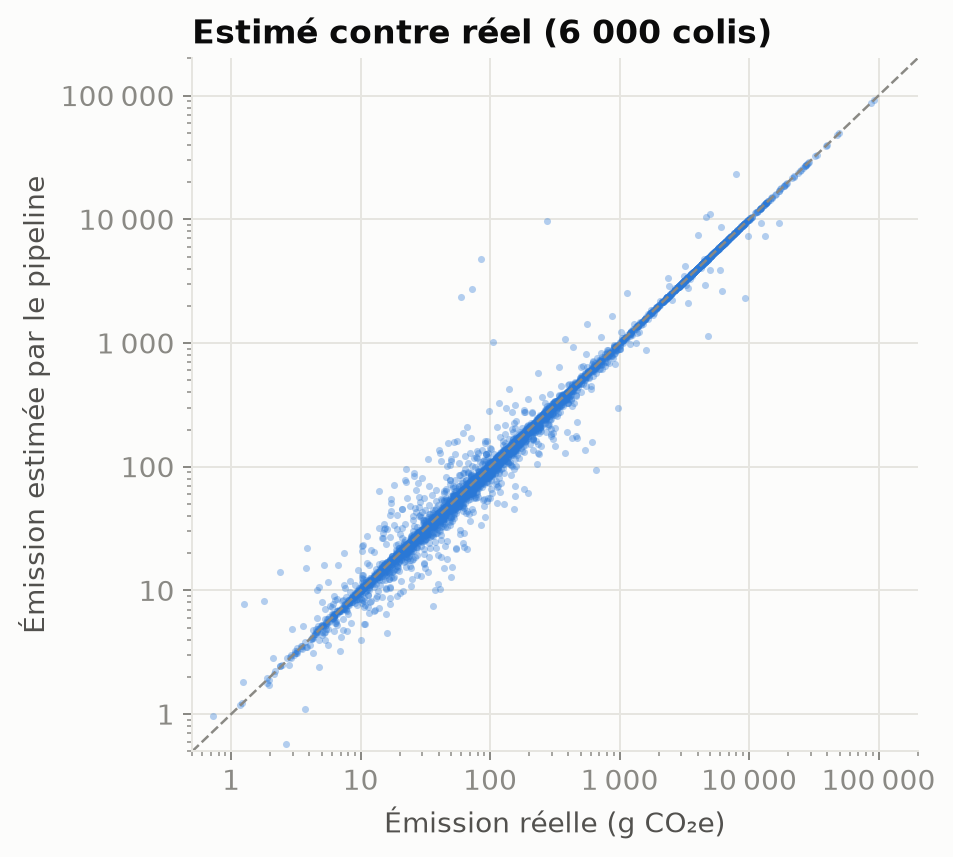

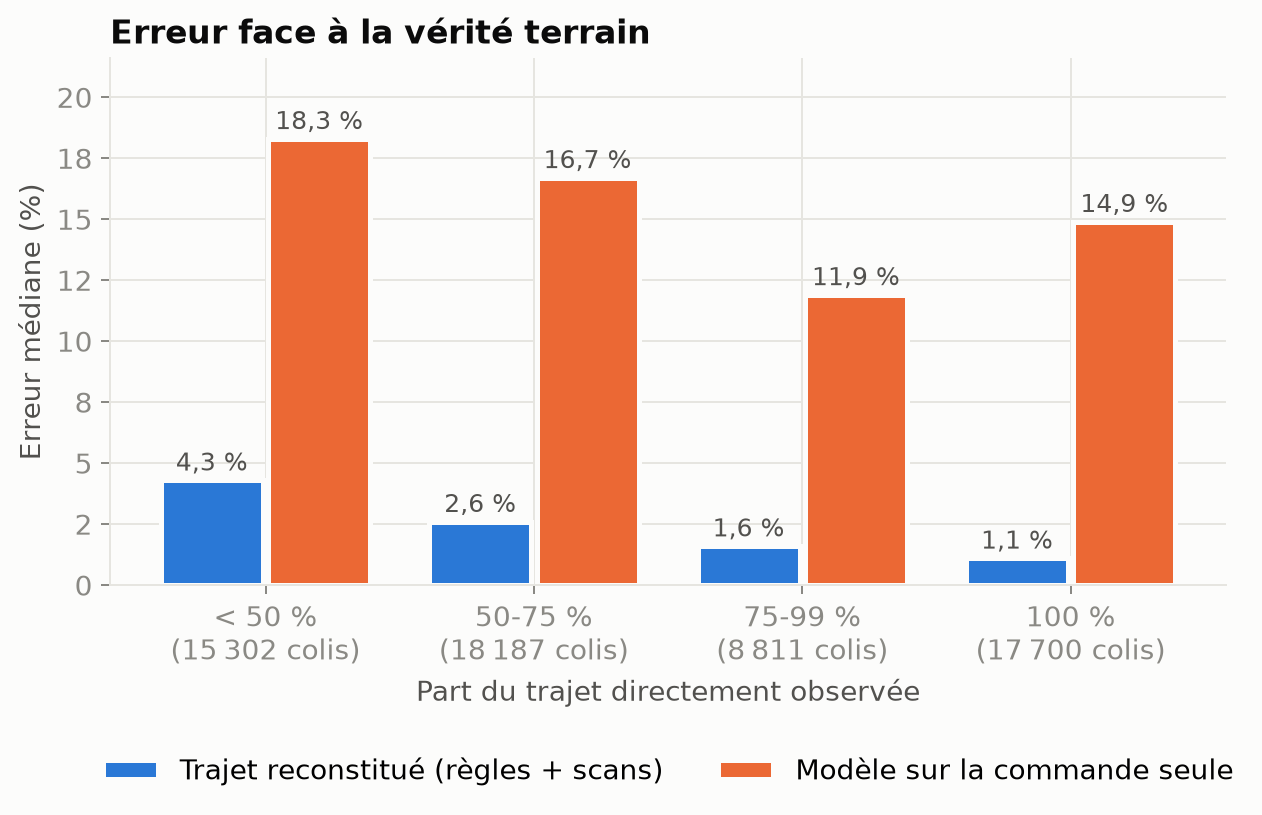

In [17]:
display(Image(C.FIGURES / "05_estime_vs_reel.png", width=480))
display(Image(C.FIGURES / "04_erreur_par_observation.png", width=700))

In [18]:
pd.DataFrame(ev["defauts"])

,defaut,injectes,traites
0,SAP : doublons supprimés,1020,1020
1,SAP : grammes saisis en kg (inclut les grammes...,1166,1334
2,SAP : poids manquants (+ imputés par médiane),1542,1539
3,SAP : poids nuls ou négatifs,129,132
4,Scans : doubles flashages,10611,10539
5,Scans : GPS inversés,6871,7048
6,Scans : GPS à zéro,3531,3634
7,Scans : orphelins,300,300
8,Scans : transporteur tronqué,7607,7838
9,Scans : horloge décalée,1402,1464


## 7. Analyse et publication

La table Curated est publiée en Parquet et en CSV, avec un bilan Excel par client et l'interface Streamlit (`python run_app.py`).

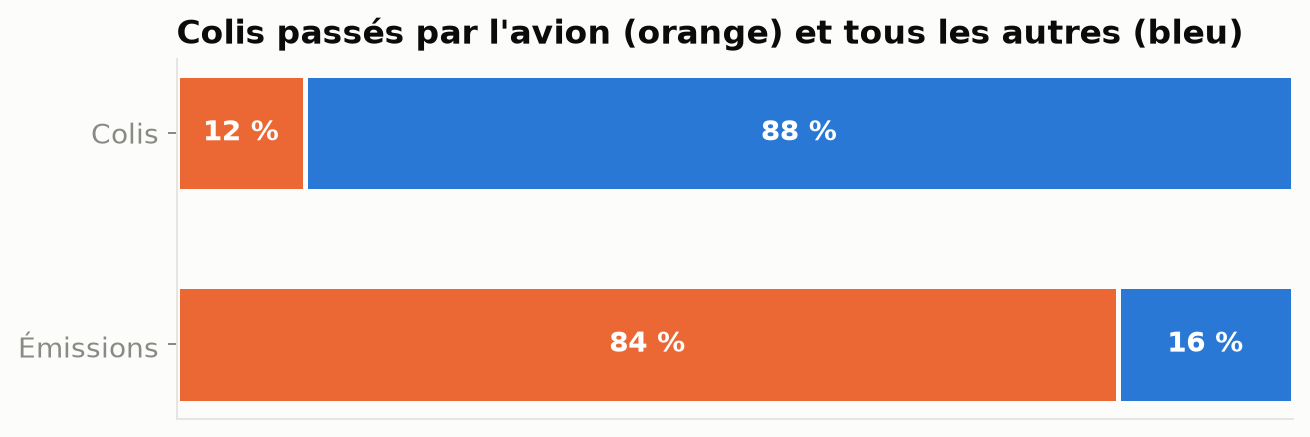

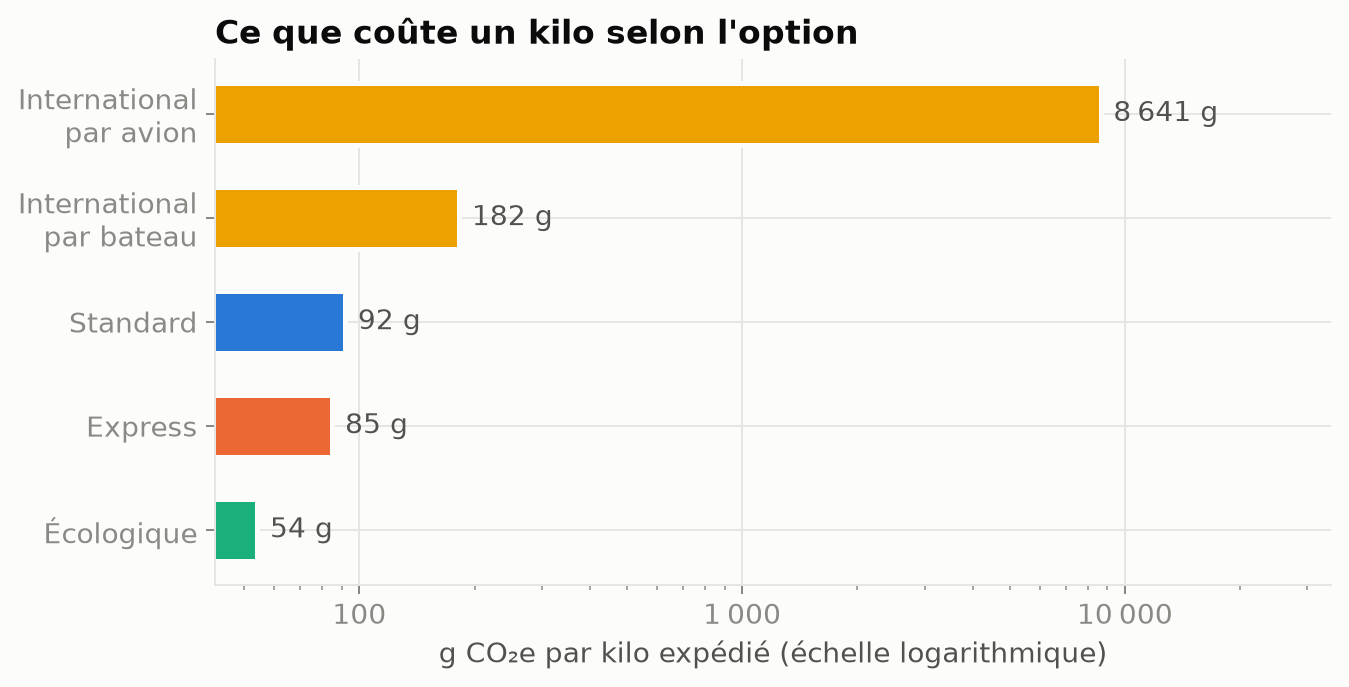

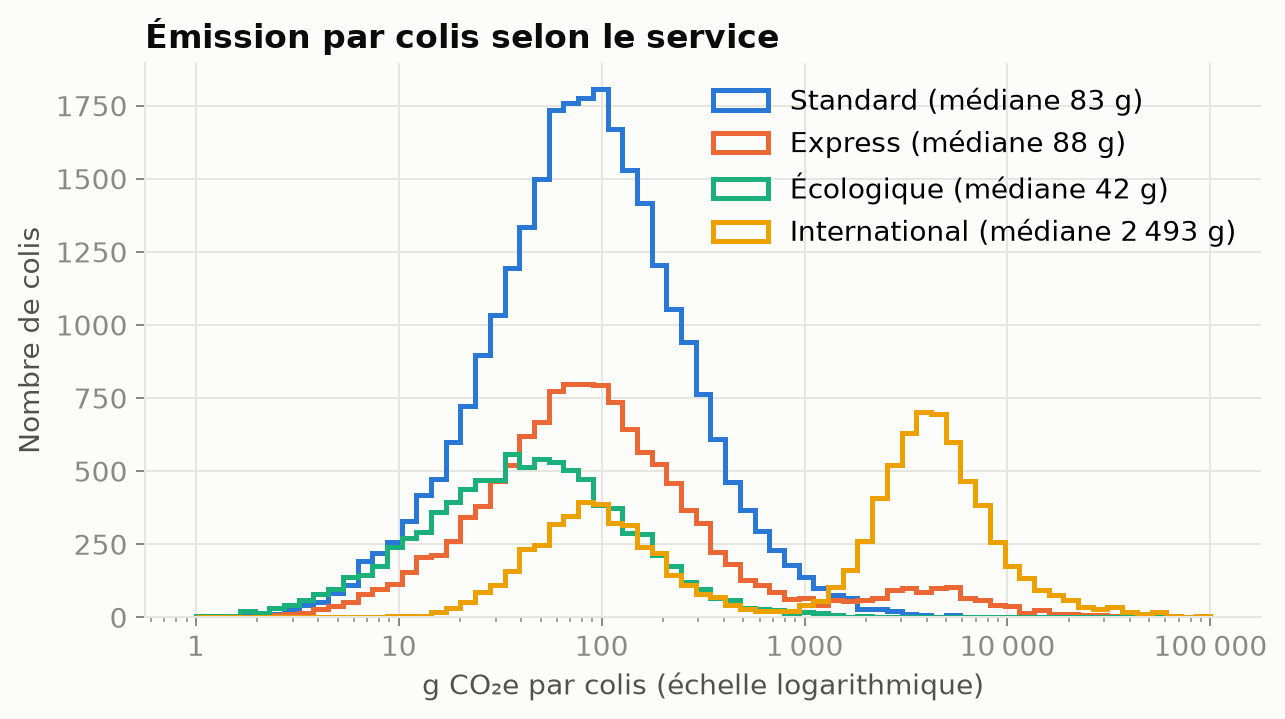

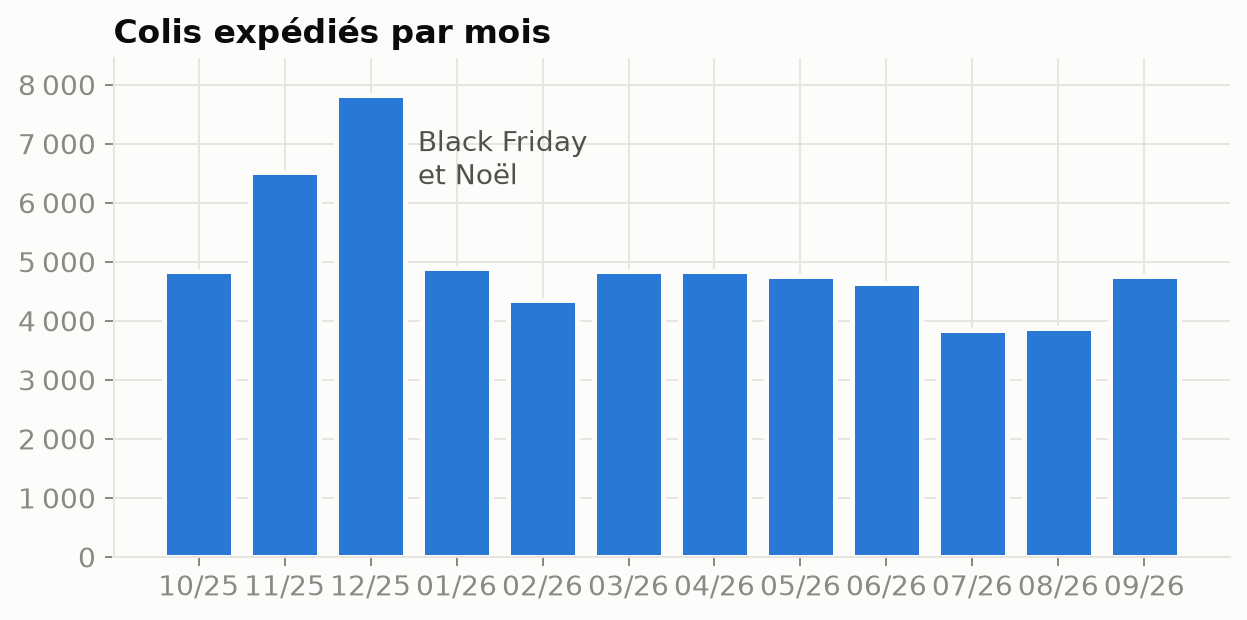

In [19]:
for f in ["01_colis_vs_emissions_avion", "06_g_par_kg", "02_distribution_par_service", "03_colis_par_mois"]:
    display(Image(C.FIGURES / f"{f}.png", width=700))

In [20]:
bilan = cur.groupby("client").agg(colis=("tracking_id", "size"),
                                  t_co2e=("emission_estimee_g", lambda s: round(s.sum() / 1e6, 2)),
                                  g_par_colis=("emission_estimee_g", lambda s: round(s.mean())),
                                  part_avion=("emission_avion_g", lambda s: round(s.sum() / cur.loc[s.index, "emission_estimee_g"].sum(), 3)))
bilan.sort_values("t_co2e", ascending=False)

,colis,t_co2e,g_par_colis,part_avion
client,,,,
SHEIN,6052,24.55,4056,0.991
AMAZON,19771,17.52,886,0.867
CDISCOUNT,6608,3.66,554,0.657
VINTED,13142,1.27,96,0.000
LEROY MERLIN,1787,1.19,665,0.000
DECATHLON,4725,0.92,195,0.000
ZALANDO,4875,0.42,86,0.000
BACK MARKET,3040,0.17,55,0.000


## Conclusions

* L'avion concentre l'essentiel des émissions alors qu'il ne concerne qu'une minorité de colis : c'est le
  premier sujet à traiter avec les clients qui importent d'Asie.
* Sur le territoire, l'option écologique (train, véhicules électriques, vélos cargo) divise l'émission par
  kilo par près de deux ; l'express n'émet pas plus que le standard.
* Le trajet reconstitué à partir des scans est précis à quelques pourcents, même quand la moitié du trajet
  n'est pas observée : la topologie du réseau, apprise dans les données, comble les trous.
* Le modèle qui n'utilise que la commande (avant expédition) se trompe de 15 à 18 % en médiane : il sert
  d'estimation a priori et de garde-fou pour repérer les reconstitutions douteuses.